# 09 Paper figures and tables

Collects the figures of notebooks 01 to 08 under manuscript numbers and builds the manuscript tables. Run after all other notebooks. Nothing is refitted.

- Figures: `figures/paper/main/`, `figures/paper/supplementary/`
- Tables: `tables/main/`, `tables/supplementary/`

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

from src.config import DATA_PROC, FIGURES, RESULTS, TABLES
from src.features import make_table

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
Image.MAX_IMAGE_PIXELS = None

MET, STATS = RESULTS / "metrics", RESULTS / "stats"
FIG_MAIN, FIG_SUP = FIGURES / "paper" / "main", FIGURES / "paper" / "supplementary"
TAB_MAIN, TAB_SUP = TABLES / "main", TABLES / "supplementary"
for p in (FIG_MAIN, FIG_SUP, TAB_MAIN, TAB_SUP):
    p.mkdir(parents=True, exist_ok=True)

NAMES = {"sed_mean": "Baseline (time mean)", "linear": "Linear", "ridge_poly": "Polynomial ridge", "svr": "SVR",
         "rf": "Random forest", "et": "Extra trees", "hgb": "Gradient boosting", "mlp": "MLP", "gp": "Gaussian process",
         "tabpfn": "TabPFN"}
for r, lab in [("linear", "linear"), ("ridge_poly", "polynomial ridge"), ("svr", "SVR"), ("et", "extra trees"), ("mlp", "MLP")]:
    NAMES[f"hyb_san_{r}"] = f"Hybrid San + {lab}"
    NAMES[f"hyb_san_floor_{r}"] = f"Hybrid San-floor + {lab}"

## 1. Figure list

In [2]:
MAIN = [
    ("Fig01", "settling_curves_by_day", ["eda/fig05_settling_curves_by_day"]),
    ("Fig02", "kinetic_fit_quality", ["kinetics/fig02_fit_quality"]),
    ("Fig03", "random_vs_day_split_ranks", ["stats/fig02_random_vs_lodo"]),
    ("Fig04", "hybrid_vs_direct", ["hybrid/fig01_hybrid_vs_direct"]),
    ("Fig05", "friedman_ranks", ["stats/fig01_friedman_ranks"]),
    ("Fig06", "hybrid_parameters", ["xai/fig04_hybrid_parameters", "hybrid/fig02_parameter_predictability"]),
    ("Fig07", "ale_and_shap", ["xai/fig03_ale", "xai/fig05_shap_beeswarm"]),
    ("Fig08", "dose_recommendation", ["dose/fig01_dose_recommendation"]),
]
SUP = [
    ("FigS01", "design_map", "eda/fig01_design_map"),
    ("FigS02", "replicate_noise", "eda/fig02_replicate_noise"),
    ("FigS03", "distributions", "eda/fig03_distributions"),
    ("FigS04", "t0_and_removal_by_day", "eda/fig04_t0_removal_by_day"),
    ("FigS05", "normalised_curves", "eda/fig06_normalised_curves"),
    ("FigS06", "dose_response_by_day", "eda/fig07_dose_response_by_day"),
    ("FigS07", "outliers", "eda/fig08_outliers"),
    ("FigS08", "correlations", "eda/fig09_correlations"),
    ("FigS09", "variance_between_days", "eda/fig10_variance_by_day"),
    ("FigS10", "feature_space_coverage", "eda/fig11_coverage"),
    ("FigS11", "kinetic_residuals_by_time", "kinetics/fig01_residuals_by_time"),
    ("FigS12", "kinetic_example_fits", "kinetics/fig03_example_fits"),
    ("FigS13", "kinetic_parameters_vs_dose", "kinetics/fig04_params_vs_dose"),
    ("FigS14", "direct_model_scores", "models/fig01_model_scores"),
    ("FigS15", "per_day_rmse", "models/fig02_per_day_rmse"),
    ("FigS16", "observed_vs_predicted", "models/fig03_obs_vs_pred_best"),
    ("FigS17", "hybrid_example_curves", "hybrid/fig03_example_curves"),
    ("FigS18", "full_feature_gain_seen_unseen", "stats/fig03_full_gain_seen_unseen"),
    ("FigS19", "shap_importance", "xai/fig01_shap_importance"),
    ("FigS20", "shap_dose_dependence", "xai/fig02_shap_dose"),
    ("FigS21", "shap_waterfall", "xai/fig06_shap_waterfall"),
    ("FigS22", "one_jar_calibration", "dose/fig02_one_jar_calibration"),
]
missing = [s for _, _, srcs in MAIN for s in srcs if not (FIGURES / f"{s}.png").exists()]
missing += [s for _, _, s in SUP if not (FIGURES / f"{s}.png").exists()]
print("missing sources:", missing or "none")

missing sources: none


## 2. Build figures

In [3]:
def copy_figure(src, dst):
    for ext in ("png", "pdf"):
        f = FIGURES / f"{src}.{ext}"
        if f.exists():
            shutil.copy(f, dst.with_suffix(f".{ext}"))


CROP_TOP = {"hybrid/fig02_parameter_predictability": 0.09}
FONT = ImageFont.truetype(font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans", weight="bold")), 46)


def stack(srcs, dst, dpi=300):
    imgs = []
    for s in srcs:
        im = Image.open(FIGURES / f"{s}.png").convert("RGB")
        imgs.append(im.crop((0, int(CROP_TOP.get(s, 0) * im.height), im.width, im.height)))
    w, pad = max(im.width for im in imgs), 60
    canvas = Image.new("RGB", (w, sum(im.height + pad for im in imgs)), "white")
    draw, y = ImageDraw.Draw(canvas), 0
    for letter, im in zip("abcdef", imgs):
        canvas.paste(im, ((w - im.width) // 2, y + pad))
        draw.text((10, y + 5), letter, fill="black", font=FONT)
        y += im.height + pad
    canvas.save(dst.with_suffix(".png"), dpi=(dpi, dpi))
    fig = plt.figure(figsize=(canvas.width / dpi, canvas.height / dpi), dpi=dpi)
    fig.figimage(np.asarray(canvas), 0, 0)
    fig.savefig(dst.with_suffix(".pdf"), dpi=dpi)
    plt.close(fig)


rows = []
for num, name, srcs in MAIN:
    dst = FIG_MAIN / f"{num}_{name}"
    if any(not (FIGURES / f"{s}.png").exists() for s in srcs):
        continue
    if len(srcs) == 1:
        copy_figure(srcs[0], dst)
    else:
        stack(srcs, dst)
    rows.append({"figure": num, "file": dst.name, "part": "main", "sources": " + ".join(srcs)})
for num, name, src in SUP:
    dst = FIG_SUP / f"{num}_{name}"
    if (FIGURES / f"{src}.png").exists():
        copy_figure(src, dst)
        rows.append({"figure": num, "file": dst.name, "part": "supplementary", "sources": src})
fig_list = pd.DataFrame(rows)
fig_list.to_csv(FIGURES / "paper" / "figure_list.csv", index=False)
fig_list

,figure,file,part,sources
0,Fig01,Fig01_settling_curves_by_day,main,eda/fig05_settling_curves_by_day
1,Fig02,Fig02_kinetic_fit_quality,main,kinetics/fig02_fit_quality
2,Fig03,Fig03_random_vs_day_split_ranks,main,stats/fig02_random_vs_lodo
3,Fig04,Fig04_hybrid_vs_direct,main,hybrid/fig01_hybrid_vs_direct
4,Fig05,Fig05_friedman_ranks,main,stats/fig01_friedman_ranks
5,Fig06,Fig06_hybrid_parameters,main,xai/fig04_hybrid_parameters + hybrid/fig02_par...
6,Fig07,Fig07_ale_and_shap,main,xai/fig03_ale + xai/fig05_shap_beeswarm
7,Fig08,Fig08_dose_recommendation,main,dose/fig01_dose_recommendation
8,FigS01,FigS01_design_map,supplementary,eda/fig01_design_map
9,FigS02,FigS02_replicate_noise,supplementary,eda/fig02_replicate_noise


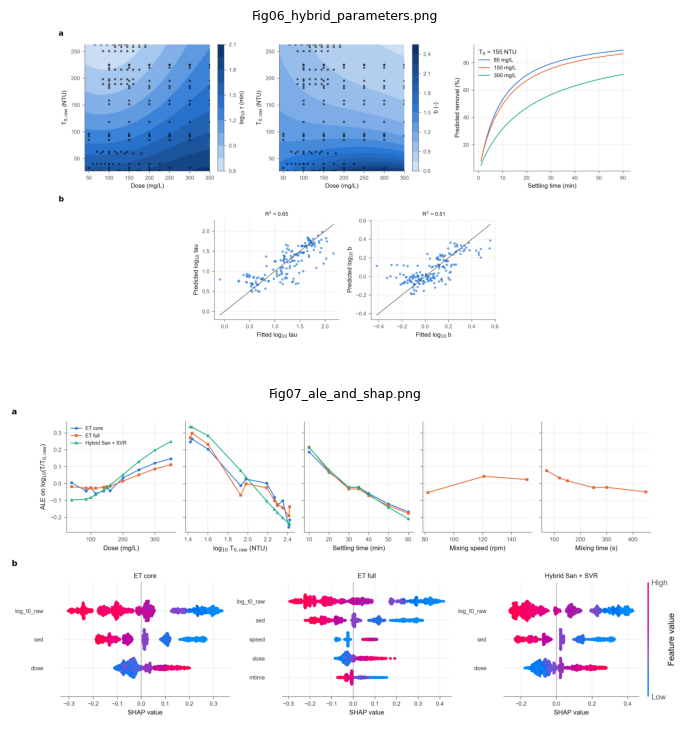

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9, 9))
for ax, num in zip(axes, ["Fig06", "Fig07"]):
    f = next(FIG_MAIN.glob(f"{num}_*.png"), None)
    if f:
        ax.imshow(Image.open(f))
        ax.set_title(f.name, fontsize=9)
    ax.axis("off")
plt.show()

## 3. Main tables

In [5]:
long = pd.read_csv(DATA_PROC / "long.csv", parse_dates=["date"])
tab = make_table(long, level="cell")
runs = pd.read_csv(DATA_PROC / "runs.csv")
eda = json.loads((STATS / "eda_key_numbers.json").read_text())
var = pd.read_csv(STATS / "variance_by_day.csv", index_col=0)
jar = tab.drop_duplicates("run")
t1 = pd.DataFrame([
    ("Sampling days", eda["days"]),
    ("Jars (runs)", eda["runs"]),
    ("Turbidity readings", eda["rows"]),
    ("Replicates per jar and time", 3),
    ("Settling times (min)", "0, 10, 20, 30, 40, 50, 60"),
    ("Coagulant dose (mg/L)", f"{runs['dose'].min():.0f} to {runs['dose'].max():.0f}"),
    ("Raw-water turbidity, batch median (NTU)", f"{jar['t0_raw'].min():.1f} to {jar['t0_raw'].max():.1f}"),
    ("Mixing speed (rpm)", ", ".join(map(str, sorted(runs["speed"].unique())))),
    ("Mixing time (s)", f"{runs['mtime'].min()} to {runs['mtime'].max()}"),
    ("Removal at 60 min, median (range) (%)", f"{eda['rem60_median']} ({eda['rem60_min']} to {eda['rem60_max']})"),
    ("Replicate CV, median at 10 to 60 min (%)", eda["replicate_cv_median_10_60min"]),
    ("Share of variance between days, log10 T at 60 min", eda["icc_log_T60"]),
], columns=["Item", "Value"])
t1.to_csv(TAB_MAIN / "Table1_dataset.csv", index=False)
t1

,Item,Value
0,Sampling days,22
1,Jars (runs),168
2,Turbidity readings,3528
3,Replicates per jar and time,3
4,Settling times (min),"0, 10, 20, 30, 40, 50, 60"
5,Coagulant dose (mg/L),40 to 350
6,"Raw-water turbidity, batch median (NTU)",26.5 to 263.2
7,Mixing speed (rpm),"82, 121, 151"
8,Mixing time (s),71 to 450
9,"Removal at 60 min, median (range) (%)",77.0 (10.7 to 94.4)


In [6]:
km = pd.read_csv(STATS / "kinetic_model_summary.csv")
ext = pd.read_csv(STATS / "kinetic_extrapolation.csv", header=[0, 1], index_col=0)
t2 = pd.DataFrame({
    "Model": km["model"].str.replace("_", " "),
    "Parameters": km["p"],
    "Median RMSE (log10 NTU)": km["rmse_median"].round(4),
    "RMSE / replicate noise": km["rmse_median_over_noise"].round(2),
    "Total AICc": km["aicc_total"].round(0),
    "Jars best by AICc": km["best_by_aicc"].astype(int),
    "Mean Akaike weight": km["mean_akaike_weight"].round(3),
    "Lack of fit rejected (%)": km["lof_reject_pct"].round(1),
    "Extrapolation RMSE, 50 to 60 min": ext[("rmse_50_60", "median")].reindex(km["model"]).round(4).to_numpy(),
})
t2.to_csv(TAB_MAIN / "Table2_kinetic_models.csv", index=False)
t2

,Model,Parameters,Median RMSE (log10 NTU),RMSE / replicate noise,Total AICc,Jars best by AICc,Mean Akaike weight,Lack of fit rejected (%),"Extrapolation RMSE, 50 to 60 min"
0,no floor,1,0.0693,3.51,-15357.0,0,0.006,96.4,0.1664
1,first order,2,0.0349,1.77,-19643.0,8,0.035,88.7,0.0680
2,first order lag,3,0.0256,1.30,-20677.0,35,0.203,64.9,0.0625
3,stretched,3,0.0208,1.06,-22537.0,22,0.181,39.3,0.0427
4,second order,2,0.0295,1.49,-20183.0,18,0.092,78.0,0.0375
5,san,2,0.0245,1.24,-22109.0,47,0.212,56.5,0.0382
6,san floor,3,0.0202,1.02,-22813.0,38,0.271,36.3,0.0290


In [7]:
sc = pd.read_csv(MET / "06_scores_ci.csv")
r2_random = sc[(sc["fset"] == "core") & (sc["split"] == "random")].set_index("model")["r2_log"]
rows = []
for fs in ["core", "full"]:
    s = sc[(sc["fset"] == fs) & (sc["split"] == "lodo")].sort_values("day_rmse")
    for _, r in s.iterrows():
        rows.append({"Inputs": fs, "Model": NAMES.get(r["model"], r["model"]),
                     "Per-day RMSE (log10 NTU)": round(r["day_rmse"], 3),
                     "95 % CI": f"{r['ci_lo']:.3f} to {r['ci_hi']:.3f}",
                     "R² (new day)": round(r["r2_log"], 2),
                     "Rising curves (%)": round(100 * r["rise_share"], 1),
                     "R² (random split)": round(r2_random.get(r["model"], np.nan), 2) if fs == "core" else np.nan})
t3 = pd.DataFrame(rows)
t3.to_csv(TAB_MAIN / "Table3_model_scores.csv", index=False)
t3

,Inputs,Model,Per-day RMSE (log10 NTU),95 % CI,R² (new day),Rising curves (%),R² (random split)
0,core,Hybrid San + SVR,0.138,0.109 to 0.172,0.68,0.0,NaN
1,core,Hybrid San-floor + linear,0.139,0.108 to 0.174,0.69,0.0,NaN
2,core,MLP,0.140,0.109 to 0.176,0.68,2.4,0.74
3,core,Hybrid San + polynomial ridge,0.141,0.112 to 0.176,0.67,0.0,NaN
4,core,Polynomial ridge,0.142,0.110 to 0.178,0.67,0.6,0.74
5,core,SVR,0.142,0.111 to 0.176,0.68,0.0,0.73
6,core,Hybrid San-floor + polynomial ridge,0.144,0.112 to 0.181,0.66,0.0,NaN
7,core,Hybrid San-floor + SVR,0.148,0.115 to 0.184,0.65,0.0,NaN
8,core,Hybrid San + MLP,0.148,0.118 to 0.182,0.66,0.0,NaN
9,core,Hybrid San-floor + extra trees,0.151,0.119 to 0.183,0.65,0.0,NaN


In [8]:
dc = pd.read_csv(MET / "08_dose_choice_summary.csv")
t4a = pd.DataFrame({
    "Strategy": dc["strategy"],
    "Mean shortfall (pp)": dc["mean_regret_pp"].round(2),
    "Median shortfall (pp)": dc["median_regret_pp"].round(2),
    "Days within 2 pp (%)": (100 * dc["share_within_2pp"]).round(0),
    "Mean dose chosen (mg/L)": dc["mean_dose"].round(0),
    "Mean dose minus best dose (mg/L)": dc["mean_dose_minus_best"].round(0),
})
cal = pd.read_csv(MET / "08_calibration_by_day.csv", index_col=0)
t4b = pd.DataFrame({"Calibration": cal.columns, "Mean per-day RMSE (log10 NTU)": cal.mean().round(4).to_numpy(),
                    "Days improved": [int((cal[c] < cal["none"]).sum()) for c in cal.columns]})
t4a.to_csv(TAB_MAIN / "Table4a_dose_choice.csv", index=False)
t4b.to_csv(TAB_MAIN / "Table4b_one_jar_calibration.csv", index=False)
display(t4a)
t4b

,Strategy,Mean shortfall (pp),Median shortfall (pp),Days within 2 pp (%),Mean dose chosen (mg/L),Mean dose minus best dose (mg/L)
0,fixed (median best dose of other days),1.09,0.19,77.0,100.0,-23.0
1,TabPFN,2.17,0.94,55.0,98.0,-26.0
2,"hybrid, lowest within 2 pp",2.26,0.76,59.0,82.0,-41.0
3,SVR,2.28,0.76,59.0,81.0,-43.0
4,MLP,2.44,0.91,55.0,86.0,-38.0
5,hybrid San + SVR,2.85,0.91,59.0,93.0,-31.0
6,random tested dose,8.41,4.93,18.0,168.0,45.0


,Calibration,Mean per-day RMSE (log10 NTU),Days improved
0,none,0.1373,0
1,"one jar, all times",0.1153,12
2,"one jar, 10 min only",0.1236,13


## 4. Supplementary tables

In [9]:
def fmt(v):
    v = pd.Series(v).dropna()
    if v.empty:
        return "None"
    if pd.api.types.is_numeric_dtype(v):
        lo, med, hi = v.min(), v.median(), v.max()
        g = lambda x: f"{x:.3g}"
        return g(med) if lo == hi else f"{g(med)} ({g(lo)} to {g(hi)})"
    return v.mode().iloc[0]


rows = []
for f in sorted((RESULTS / "predictions" / "03").glob("params__*__core__lodo.csv")):
    p = pd.read_csv(f)
    model = p["model"].iloc[0]
    for c in p.columns.drop(["fold", "model", "fset", "split"], errors="ignore"):
        rows.append({"Model": NAMES.get(model, model), "Hyperparameter": c, "Median (range) over 22 folds": fmt(p[c])})
for f in sorted((RESULTS / "predictions" / "05").glob("params__hyb_san_svr__core.csv")):
    p = pd.read_csv(f)
    for c in ["C", "gamma", "epsilon"]:
        rows.append({"Model": NAMES["hyb_san_svr"], "Hyperparameter": c, "Median (range) over 22 folds": fmt(p[c])})
ts1 = pd.DataFrame(rows)
ts1.to_csv(TAB_SUP / "TableS01_hyperparameters.csv", index=False)
ts1

,Model,Hyperparameter,Median (range) over 22 folds
0,Extra trees,max_features,0.602 (0.513 to 0.602)
1,Extra trees,min_samples_leaf,6 (2 to 6)
2,Extra trees,max_depth,None
3,Gradient boosting,learning_rate,0.0104 (0.0104 to 0.017)
4,Gradient boosting,max_leaf_nodes,4 (4 to 5)
5,Gradient boosting,min_samples_leaf,39 (39 to 44)
6,Gradient boosting,l2_regularization,1.43 (0.254 to 1.43)
7,Gradient boosting,max_iter,561 (400 to 561)
8,MLP,width,51 (9 to 62)
9,MLP,depth,2 (1 to 3)


In [10]:
pt = pd.read_csv(MET / "06_paired_tests.csv")
ts2 = pd.DataFrame({"Model A": pt["a"].map(NAMES), "Model B": pt["b"].map(NAMES),
                    "Mean difference A minus B": pt["mean_diff"].round(4), "Days A better (of 22)": pt["a_wins"],
                    "p": pt["p"].round(3), "p (Holm)": pt["p_holm"].round(3)})
fr = pd.read_csv(MET / "06_friedman_core_lodo.csv", index_col=0)
ts3 = pd.DataFrame({"Model": fr.index.map(lambda m: NAMES.get(m, m)), "Mean rank": fr["mean_rank"].round(2),
                    "p vs best": fr["p_vs_best"].round(3), "p (Holm)": fr["p_holm"].round(3)})
rv = pd.read_csv(MET / "06_random_vs_lodo.csv", index_col=0).sort_values("lodo")
ts4 = pd.DataFrame({"Model": rv.index.map(lambda m: NAMES.get(m, m)), "Random split RMSE": rv["random"].round(3),
                    "Day split RMSE": rv["lodo"].round(3), "Ratio": rv["ratio"].round(2),
                    "Rank, random": rv["rank_random"].astype(int), "Rank, day split": rv["rank_lodo"].astype(int)})
fc = pd.read_csv(MET / "06_full_vs_core.csv")
ts5 = pd.DataFrame({"Model": fc["model"].map(lambda m: NAMES.get(m, m)), "Mean change full minus core": fc["mean_diff"].round(4),
                    "Days full better (of 22)": fc["a_wins"], "p (Holm)": fc["p_holm"].round(3),
                    "Gain, seen settings": fc["gain_seen"].round(4), "Gain, unseen settings": fc["gain_unseen"].round(4)})
iv = pd.read_csv(MET / "06_intervals.csv", index_col=0)
ts6 = pd.DataFrame({"Model": iv.index.map(lambda m: NAMES.get(m, m)), "Coverage of 90 % interval": iv["coverage"].round(3),
                    "Worst-day coverage": iv["min_day_coverage"].round(3), "Mean width (log10 NTU)": iv["width_log"].round(3)})
for t, name in [(ts2, "TableS02_paired_tests"), (ts3, "TableS03_friedman_ranks"), (ts4, "TableS04_random_vs_day_split"),
                (ts5, "TableS05_full_vs_core"), (ts6, "TableS06_prediction_intervals")]:
    t.to_csv(TAB_SUP / f"{name}.csv", index=False)
display(ts2, ts4)

,Model A,Model B,Mean difference A minus B,Days A better (of 22),p,p (Holm)
0,Hybrid San + linear,Linear,-0.0000,12,0.949,1.000
1,Hybrid San + polynomial ridge,Polynomial ridge,-0.0006,12,0.443,1.000
2,Hybrid San + SVR,SVR,-0.0042,11,0.849,1.000
3,Hybrid San + extra trees,Extra trees,-0.0062,15,0.063,0.571
4,Hybrid San + MLP,MLP,0.0082,8,0.105,0.738
5,Hybrid San-floor + linear,Hybrid San + linear,-0.0117,17,0.030,0.301
6,Hybrid San-floor + polynomial ridge,Hybrid San + polynomial ridge,0.0030,10,0.198,1.000
7,Hybrid San-floor + SVR,Hybrid San + SVR,0.0101,8,0.079,0.635
8,Hybrid San-floor + extra trees,Hybrid San + extra trees,-0.0006,14,0.610,1.000
9,Hybrid San-floor + MLP,Hybrid San + MLP,0.0063,11,0.899,1.000


,Model,Random split RMSE,Day split RMSE,Ratio,"Rank, random","Rank, day split"
model,,,,,,
mlp,MLP,0.126,0.140,1.11,6,1
ridge_poly,Polynomial ridge,0.128,0.142,1.11,8,2
svr,SVR,0.127,0.142,1.12,7,3
linear,Linear,0.144,0.151,1.05,9,4
hgb,Gradient boosting,0.042,0.155,3.73,3,5
rf,Random forest,0.078,0.157,2.02,4,6
et,Extra trees,0.085,0.157,1.86,5,7
tabpfn,TabPFN,0.023,0.159,6.89,1,8
sed_mean,Baseline (time mean),0.254,0.262,1.03,10,9


In [11]:
ident = pd.read_csv(STATS / "kinetic_identifiability.csv")
ts7 = pd.DataFrame({"Model": ident["model"].str.replace("_", " "), "Parameter": ident["param"],
                    "Median": ident["median"].round(3), "10th to 90th percentile": ident["q10"].round(3).astype(str) + " to " + ident["q90"].round(3).astype(str),
                    "At bound (%)": ident["at_bound_pct"].round(1), "Median relative SE": ident["median_rel_se_free"].round(3)})
shap_imp = pd.read_csv(MET / "07_shap_importance.csv", index_col=0)
ts8 = (shap_imp / shap_imp.sum()).round(3).rename(index={"dose": "Dose", "log_t0_raw": "log10 raw turbidity", "sed": "Settling time", "speed": "Mixing speed", "mtime": "Mixing time"}).rename_axis("Feature").reset_index()
rd = pd.read_csv(MET / "08_recommended_dose.csv")
ts9 = rd.rename(columns={"t0_raw": "Raw turbidity (NTU)", "dose_min_tested": "Lowest tested dose", "dose_max_tested": "Highest tested dose",
                         "best_dose": "Dose for maximum removal", "removal_best": "Maximum removal at 60 min",
                         "lean_dose": "Lowest dose within 2 pp", "removal_lean": "Removal at that dose",
                         "t_target_best": "Minutes to 60 % removal"}).round(3)
for t, name in [(ts7, "TableS07_kinetic_identifiability"), (ts8, "TableS08_shap_importance_share"),
                (ts9, "TableS09_recommended_dose")]:
    t.to_csv(TAB_SUP / f"{name}.csv", index=False)
display(ts8)
ts9.iloc[::3]

,Feature,ET core,ET full,Hybrid San + SVR
0,Dose,0.189,0.095,0.215
1,log10 raw turbidity,0.455,0.409,0.459
2,Mixing time,NaN,0.070,NaN
3,Settling time,0.356,0.296,0.326
4,Mixing speed,NaN,0.130,NaN


,Raw turbidity (NTU),Lowest tested dose,Highest tested dose,Dose for maximum removal,Maximum removal at 60 min,Lowest dose within 2 pp,Removal at that dose,Minutes to 60 % removal
0,30.0,40.0,300.0,85.0,0.588,40.0,0.577,61.711
3,60.0,70.0,180.0,85.0,0.740,70.0,0.739,38.884
6,90.0,50.0,350.0,75.0,0.823,50.0,0.821,25.392
9,120.0,50.0,350.0,60.0,0.868,50.0,0.867,18.010
12,150.0,85.0,350.0,85.0,0.889,85.0,0.889,13.487
15,180.0,85.0,350.0,85.0,0.904,85.0,0.904,10.630
18,210.0,65.0,350.0,65.0,0.918,65.0,0.918,8.731
21,240.0,65.0,350.0,65.0,0.925,65.0,0.925,7.375


In [12]:
print(sorted(p.name for p in TAB_MAIN.glob("*.csv")))
print(sorted(p.name for p in TAB_SUP.glob("*.csv")))

['Table1_dataset.csv', 'Table2_kinetic_models.csv', 'Table3_model_scores.csv', 'Table4a_dose_choice.csv', 'Table4b_one_jar_calibration.csv']
['TableS01_hyperparameters.csv', 'TableS02_paired_tests.csv', 'TableS03_friedman_ranks.csv', 'TableS04_random_vs_day_split.csv', 'TableS05_full_vs_core.csv', 'TableS06_prediction_intervals.csv', 'TableS07_kinetic_identifiability.csv', 'TableS08_shap_importance_share.csv', 'TableS09_recommended_dose.csv']
